# **parking_vision** *(PKLot)*


In [1]:
from pathlib import Path
import subprocess, sys, os

REPO_URL = "https://github.com/173eiei/fundl-project.git"
PROJECT_DIR = Path("/content/fundl-project")
if not (PROJECT_DIR / ".git").exists():
    subprocess.run(["git", "clone", REPO_URL, str(PROJECT_DIR)], check=True)
else:
    subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=True)
os.chdir(PROJECT_DIR)
print("Project:", PROJECT_DIR)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
import torch, pandas as pd, matplotlib.pyplot as plt
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Project: /content/fundl-project
PyTorch: 2.11.0+cu130
CUDA available: True


## 1. ตั้งค่าสภาพแวดล้อมและการทำงานแบบทำซ้ำได้

Select **Runtime → Change runtime type → T4 GPU** if available. Seed 42 is used by preprocessing and training.

In [2]:
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Training can run on CPU, but will be much slower.")
print("Device:", DEVICE, "| Seed:", SEED)

GPU: Tesla T4
Device: cuda | Seed: 42


## 2. ดาวน์โหลดชุดข้อมูล PKLot

The original archive is approximately 4.6 GB. It is stored under /content, not in the Git repository. The official UFPR URL is tried first; a Hugging Face mirror fallback is provided below.

In [3]:
ARCHIVE = Path("/content/PKLot.tar.gz")
OFFICIAL_URL = "https://www.inf.ufpr.br/vri/databases/PKLot.tar.gz"
# -c resumes an interrupted download if the cell is run again.
result = subprocess.run(["wget", "-c", "-O", str(ARCHIVE), OFFICIAL_URL])
official_download_ok = (
    result.returncode == 0 and ARCHIVE.exists() and ARCHIVE.stat().st_size > 0
)
if not official_download_ok:
    print("Official download did not complete; use the mirror fallback cell below.")
else:
    print(f"Archive size: {ARCHIVE.stat().st_size / (1024**3):.2f} GiB")

Archive size: 4.56 GiB


In [4]:
# Fallback only if the official UFPR host cannot be reached.
# The mirror describes its PKLot.tar.gz as byte-for-byte identical to the original archive.
if not official_download_ok:
    if ARCHIVE.exists():
        ARCHIVE.unlink()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"], check=True)
    from huggingface_hub import hf_hub_download
    downloaded = hf_hub_download(
        repo_id="teenygrad/pklot", filename="PKLot.tar.gz",
        repo_type="dataset", local_dir="/content/pklot_mirror",
    )
    ARCHIVE = Path(downloaded)
    print("Using mirror archive:", ARCHIVE)
else:
    print("Official archive already downloaded; fallback not needed.")

Official archive already downloaded; fallback not needed.


## 3. แตกไฟล์และตรวจสอบชุดข้อมูล

The preparation script supports the segmented crop folders when present. If only full-scene images and XML annotations are present, it generates perspective-corrected parking-space crops from the four-point XML contours.

In [6]:
DATA_ROOT = Path("/content/pklot")
DATA_ROOT.mkdir(parents=True, exist_ok=True)
if not any(DATA_ROOT.iterdir()):
    subprocess.run(["tar", "-xzf", str(ARCHIVE), "-C", str(DATA_ROOT)], check=True)
segmented_dirs = [p for p in DATA_ROOT.rglob("*") if p.is_dir() and p.name.lower() == "pklotsegmented"]
xml_count = sum(1 for _ in DATA_ROOT.rglob("*.xml"))
print("Dataset root:", DATA_ROOT)
print("PKLotSegmented directories:", len(segmented_dirs))
print("XML annotations:", xml_count)
if not segmented_dirs and xml_count == 0:
    raise RuntimeError("Could not find segmented crops or PKLot XML annotations after extraction.")

Dataset root: /content/pklot
PKLotSegmented directories: 1
XML annotations: 9139


## 4. เตรียมภาพช่องจอดและแบ่งชุดข้อมูล

เลือกภาพช่องจอดไม่เกิน **10,000 ภาพรวมทั้งหมด** แล้วแบ่งเป็น Train 70%, Validation 15% และ Test 15% โดยจัดกลุ่มตามวันที่ถ่ายภาพ เพื่อไม่ให้ภาพจากวันเดียวกันกระจายไปอยู่คนละชุด

In [8]:
subprocess.run([
    sys.executable, "-m", "src.prepare_data",
    "--dataset-root", str(DATA_ROOT),
    "--output-dir", "data/processed",
    "--seed", str(SEED),
    "--max-crops", "10000",
], check=True)
MANIFEST = Path("data/processed/manifest.csv")
manifest = pd.read_csv(MANIFEST)
display(manifest.groupby(["split", "site", "class_name"]).size().rename("samples").reset_index())
print("Unique dates by split:")
display(manifest.groupby("split")["date"].nunique())

,split,site,class_name,samples
0,test,PUCPR,empty,509
1,test,PUCPR,occupied,383
2,test,UFPR04,empty,89
3,test,UFPR04,occupied,112
4,test,UFPR05,empty,192
5,test,UFPR05,occupied,201
6,train,PUCPR,empty,2443
7,train,PUCPR,occupied,1926
8,train,UFPR04,empty,607
9,train,UFPR04,occupied,515


Unique dates by split:


,date
split,
test,16
train,70
val,15


## 5. ตรวจสอบตัวอย่างภาพและสัดส่วนคลาส

Check that crops and folder labels look sensible before training. These examples are sampled from the training split only.

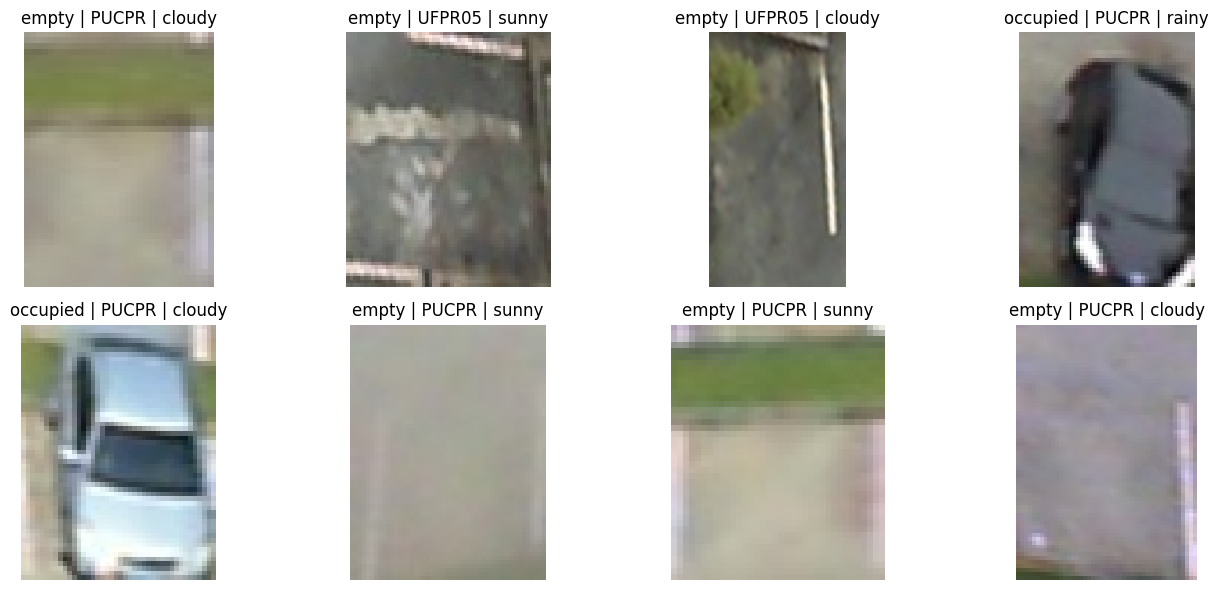

class_name,empty,occupied
split,,
test,790,696
train,3599,3431
val,755,729


In [9]:
from PIL import Image

train_rows = manifest[manifest["split"] == "train"]
sample_rows = train_rows.sample(n=min(8, len(train_rows)), random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    with Image.open(row["path"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{row['class_name']} | {row['site']} | {row['weather']}")
    ax.axis("off")
for ax in axes.flat[len(sample_rows):]:
    ax.axis("off")
plt.tight_layout()
plt.show()
display(manifest.groupby(["split", "class_name"]).size().unstack(fill_value=0))

## 6. สร้างผลลัพธ์พื้นฐานเพื่อใช้เปรียบเทียบ

The majority class is learned from **training labels only**. This cell reports its performance on validation data; it does not use the test set.

In [10]:
subprocess.run([sys.executable, "-m", "src.baseline", "--manifest", str(MANIFEST)], check=True)
baseline = pd.read_json("outputs/results/baseline_validation.json", typ="series")
display(baseline.to_frame("value"))

,value
baseline,majority_class
majority_label,0
majority_class,Empty
training_class_counts,"{'0': 3599, '1': 3431}"
validation_samples,1484
validation_accuracy,0.50876
validation_f1_binary_occupied,0.0


## 7. ฝึกโมเดล CNN ด้วยข้อมูลของเราเอง

ใช้ข้อมูลรวมไม่เกิน 10,000 ภาพ และใช้ภาพทั้งหมดในแต่ละชุดที่แบ่งไว้ โดยคงขนาดภาพและโครงสร้างโมเดลเดิมไว้ เพื่อให้เห็นผลของการลดจำนวนข้อมูลต่อเวลาเทรนและ Accuracy

In [11]:
subprocess.run([
    sys.executable, "-m", "src.train",
    "--manifest", str(MANIFEST),
    "--epochs", "20",
    "--batch-size", "64",
    "--image-size", "128",
    "--learning-rate", "0.001",
    "--weight-decay", "0.0001",
    "--patience", "5",
    "--max-train-samples", "0",
    "--max-val-samples", "0",
    "--seed", str(SEED),
], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'src.train', '--manifest', 'data/processed/manifest.csv', '--epochs', '20', '--batch-size', '64', '--image-size', '128', '--learning-rate', '0.001', '--weight-decay', '0.0001', '--patience', '5', '--max-train-samples', '0', '--max-val-samples', '0', '--seed', '42'], returncode=0)

## 8. ตรวจสอบกราฟการเรียนรู้

Use train/validation curves to discuss overfitting and justify regularization. Hyperparameter choices must be made using validation data only.

,epoch,train_loss,train_accuracy,train_f1_occupied,val_loss,val_accuracy,val_f1_occupied,learning_rate
14,15,0.040748,0.988762,0.988526,0.071126,0.982480,0.982143,0.00050
15,16,0.034483,0.989900,0.989679,0.054247,0.989218,0.989071,0.00050
16,17,0.028692,0.992034,0.991853,0.041662,0.986523,0.986413,0.00025
17,18,0.028435,0.990896,0.990687,0.078866,0.985175,0.984932,0.00025
18,19,0.024937,0.993172,0.993015,0.043374,0.989218,0.989041,0.00025


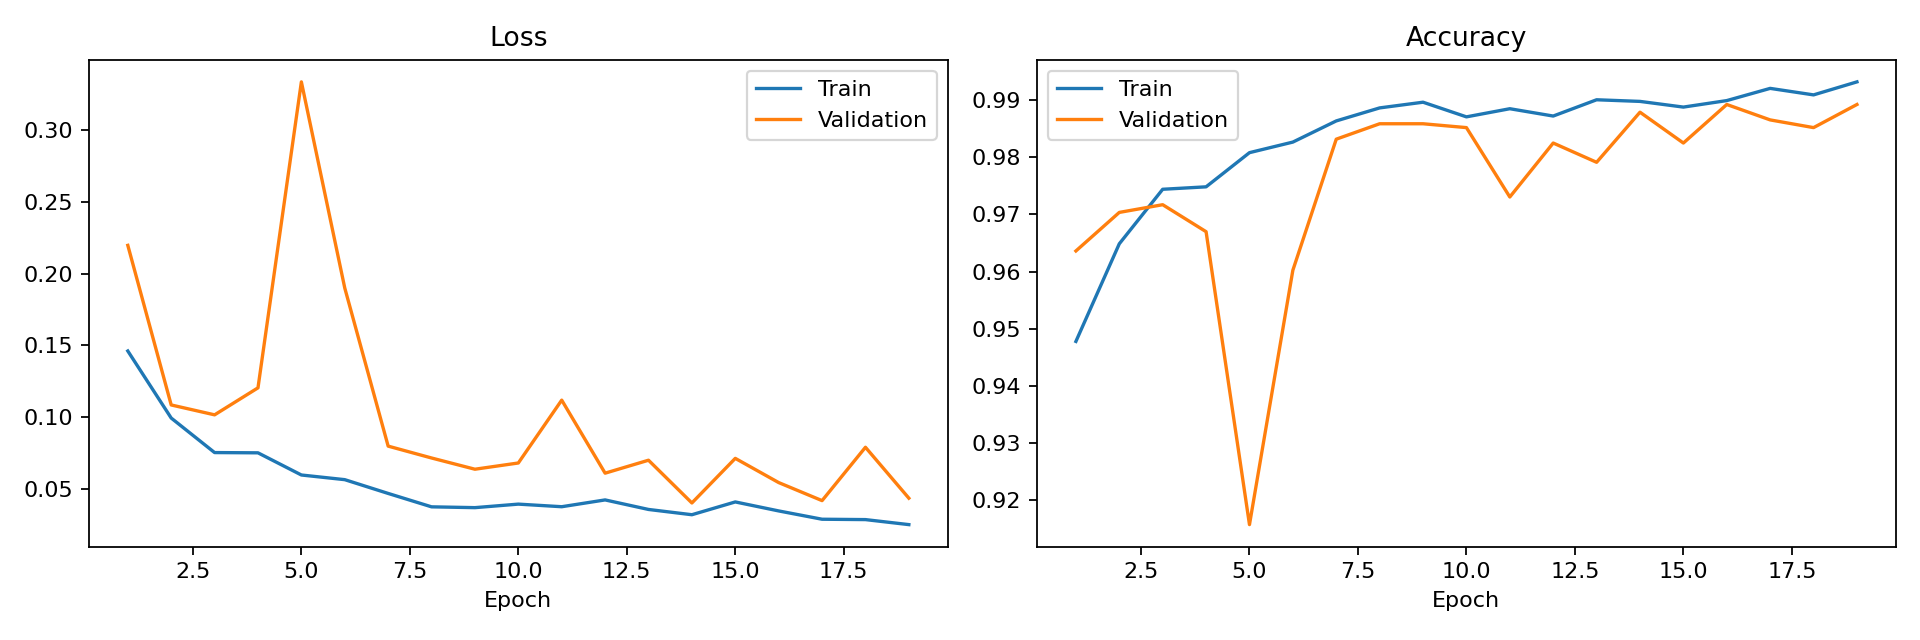

In [12]:
history = pd.read_csv("outputs/results/history.csv")
display(history.tail())
from IPython.display import display, Image as DisplayImage
display(DisplayImage(filename="outputs/results/learning_curves.png"))

## 9. ประเมินผลบนชุดทดสอบที่กันไว้

**ห้ามนำผลชุดทดสอบไปปรับแต่งโมเดล** ชุดทดสอบประกอบด้วยวันที่ถ่ายภาพที่ไม่เคยใช้ใน Train/Validation โดยรายงาน Accuracy, Precision, Recall, F1, เปรียบเทียบกับ Baseline, Confusion Matrix และตัวอย่างภาพที่ทำนายผิด

In [13]:
subprocess.run([
    sys.executable, "-m", "src.evaluate",
    "--manifest", str(MANIFEST),
    "--checkpoint", "outputs/models/best.pt",
    "--max-test-samples", "0",
    "--seed", str(SEED),
], check=True)
test_metrics = pd.read_json("outputs/results/test_metrics.json", typ="series")
display(test_metrics)

,0
test_protocol,held-out capture dates across the available PK...
test_samples,1486
test_population_samples_before_sampling,1486
test_sampling_seed,42
test_is_random_subset,False
model,"{'accuracy': 0.9858681022880211, 'precision_oc..."
majority_baseline,"{'class': 'Empty', 'label': 0, 'accuracy': 0.5..."
classification_report,"{'Empty': {'precision': 0.997412677878395, 're..."
checkpoint_best_epoch,14
checkpoint_validation_loss,0.040037


## 10. ทดลองทำนายภาพช่องจอดหนึ่งภาพ

อัปโหลดภาพที่ตัดมาเฉพาะช่องจอดรถ 1 ช่อง (ไม่ใช่ภาพลานจอดรถทั้งภาพ) ระบบจะแสดงภาพและทำนายว่า **Empty (ว่าง)** หรือ **Occupied (มีรถจอด)** พร้อมเปอร์เซ็นต์ความน่าจะเป็น

Saving Screenshot 2026-11-01 205600.png to Screenshot 2026-11-01 205600.png


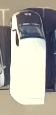

ผลการทำนาย: Occupied
ความน่าจะเป็นช่องว่าง (Empty): 4.33%
ความน่าจะเป็นมีรถจอด (Occupied): 95.67%


In [24]:
from google.colab import files
from pathlib import Path
from PIL import Image as PILImage
from IPython.display import display
import numpy as np
import torch
from src.model import ParkingCNN

uploaded = files.upload()

if uploaded:
    image_name = next(iter(uploaded))
    checkpoint_path = Path("outputs/models/best.pt")
    if not checkpoint_path.is_file():
        raise FileNotFoundError(
            "ยังไม่พบโมเดลที่ฝึกเสร็จแล้ว กรุณารันเซลล์ฝึกโมเดลก่อน"
        )

    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )
    image_size = int(checkpoint.get("image_size", 128))
    class_names = checkpoint.get("class_names", ["Empty", "Occupied"])
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    with PILImage.open(image_name) as source:
        original_image = source.convert("RGB")
        model_image = original_image.resize(
            (image_size, image_size), PILImage.Resampling.BILINEAR
        )

    display(original_image)

    image_array = np.asarray(model_image, dtype=np.float32) / 255.0
    image_array = (image_array - 0.5) / 0.5
    image_tensor = torch.from_numpy(
        image_array.transpose(2, 0, 1).copy()
    ).unsqueeze(0).to(device)

    model = ParkingCNN(num_classes=2).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    with torch.no_grad():
        probabilities = torch.softmax(
            model(image_tensor), dim=1
        )[0].cpu().numpy()

    prediction = int(probabilities.argmax())
    print("ผลการทำนาย:", class_names[prediction])
    print(f"ความน่าจะเป็นช่องว่าง (Empty): {probabilities[0] * 100:.2f}%")
    print(f"ความน่าจะเป็นมีรถจอด (Occupied): {probabilities[1] * 100:.2f}%")
else:
    print("ยังไม่ได้เลือกภาพ")
